# Case study 2 · Binary ANN: will an airline passenger be satisfied?

**Data:** `data/airline_passenger_satisfaction.csv` (103,904 passengers, 25 columns) · **Companion to:** case study 1 (same workflow, but **binary** instead of multi-class)

**The question:** from a passenger's profile (age, loyalty, travel type, class, flight distance), their 1–5 ratings of 14 services (wifi, seat comfort, online boarding, …) and the delays, predict **satisfied** vs **neutral or dissatisfied**.

What changes compared with the multi-class case study:

| | Forest cover (case study 1) | Airline satisfaction (this one) |
|---|---|---|
| classes | 7 (one of them) | 2 (yes / no) |
| output layer | 7 units, **softmax** | **1 unit, sigmoid** |
| loss | sparse categorical cross-entropy | **binary cross-entropy** |
| prediction | argmax of 7 probabilities | probability ≥ **threshold** (0.5 by default) |
| extra work | none | **text columns to encode**, **missing values**, **ID columns to drop** |

Keras 3 with the PyTorch backend, as in class. Runs in about 3–4 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import os, time
os.environ.setdefault("KERAS_BACKEND", "torch")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
import keras
from keras import layers, models, callbacks
np.random.seed(42); keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.13.2 | backend: torch


## 1 · Load and inspect

In [2]:
df = pd.read_csv("data/airline_passenger_satisfaction.csv")
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns\n")
print(df.dtypes.value_counts().to_string(), "\n")
print("text columns:", df.select_dtypes(exclude="number").columns.tolist())
print("\nmissing values:\n" + df.isnull().sum()[df.isnull().sum() > 0].to_string())
print("\ntarget balance:\n" + df["satisfaction"].value_counts(normalize=True).round(4).to_string())
df.head(3)

103,904 rows × 25 columns

int64      19
str         5
float64     1 

text columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

missing values:
Arrival Delay in Minutes    310

target balance:
satisfaction
neutral or dissatisfied    0.5667
satisfied                  0.4333


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied


- **103,904 passengers**, 25 columns: 19 integer, 1 decimal, 5 text (Gender, Customer Type, Type of Travel, Class and the target).
- **Target balance:** 56.7% "neutral or dissatisfied", 43.3% "satisfied". That's reasonably balanced, so accuracy is a fair headline metric here (unlike the forest data).
- **Only one column has missing values:** Arrival Delay (310 rows, 0.3%).

### Things to fix before any model sees the data

In [3]:
print("'Unnamed: 0' is just 0, 1, 2, ...:", bool((df["Unnamed: 0"] == np.arange(len(df))).all()))
print("'id' is unique for every row:", df["id"].is_unique)
ratings = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking", "Gate location",
           "Food and drink", "Online boarding", "Seat comfort", "Inflight entertainment", "On-board service",
           "Leg room service", "Baggage handling", "Checkin service", "Inflight service", "Cleanliness"]
zeros = (df[ratings] == 0).sum()
print("\nratings equal to 0 (outside the 1-5 scale = 'not rated / not applicable'):\n" + zeros[zeros > 0].to_string())
print(f"\ncorrelation between departure and arrival delay: {df['Departure Delay in Minutes'].corr(df['Arrival Delay in Minutes']):.3f}")

'Unnamed: 0' is just 0, 1, 2, ...: True
'id' is unique for every row: True

ratings equal to 0 (outside the 1-5 scale = 'not rated / not applicable'):
Inflight wifi service                3103
Departure/Arrival time convenient    5300
Ease of Online booking               4487
Gate location                           1
Food and drink                        107
Online boarding                      2428
Seat comfort                            1
Inflight entertainment                 14
On-board service                        3
Leg room service                      472
Checkin service                         1
Inflight service                        3
Cleanliness                            12

correlation between departure and arrival delay: 0.965


- **`Unnamed: 0` and `id` are identifiers, not information.** A row number can't cause satisfaction; keeping them invites the network to memorise noise. **Drop both.**
- **Ratings of 0** sit outside the 1–5 scale: the passenger didn't rate that service (e.g. no wifi on board). We keep them as they are (0 = "not rated"); a tree or a network can learn that 0 means something different. *(A careful alternative: add a "not rated" flag.)*
- **Arrival delay has 310 missing values.** It's almost the same as the departure delay (correlation printed above), so filling the gaps with the **median of the training set** is a safe, simple choice. Filling must happen **after** the split, using training statistics only, like scaling.

## 2 · Explore: what goes with satisfaction?

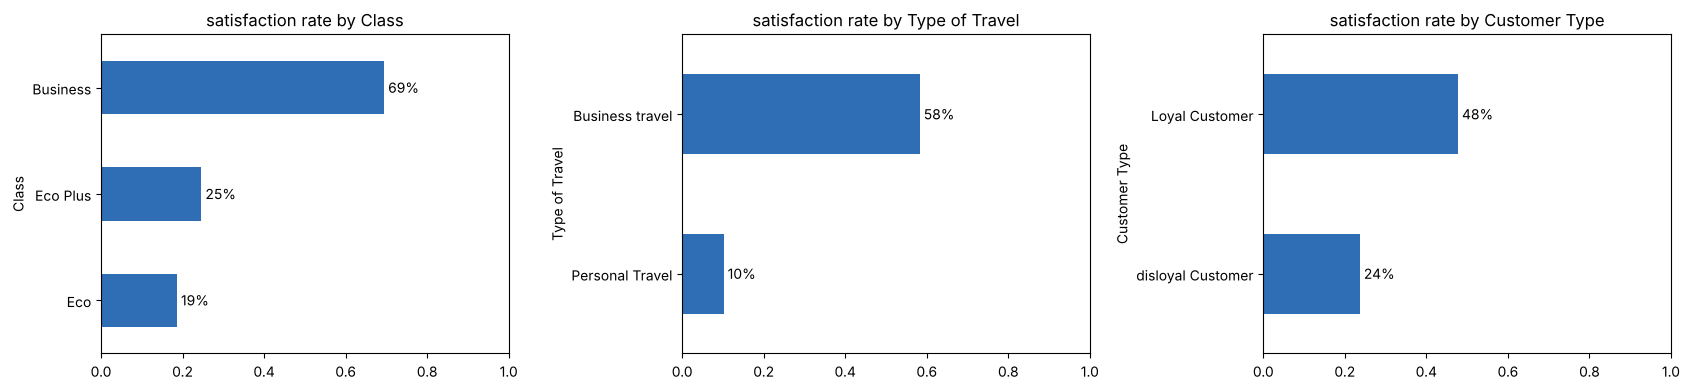

correlation of each numeric column with being satisfied:
Online boarding                      0.504
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.313
Cleanliness                          0.305
Flight Distance                      0.299
Inflight wifi service                0.284
Baggage handling                     0.248
Inflight service                     0.245
Checkin service                      0.236
Food and drink                       0.210
Ease of Online booking               0.172
Age                                  0.137
Gate location                        0.001
Departure Delay in Minutes          -0.050
Departure/Arrival time convenient   -0.052


In [4]:
df["satisfied"] = (df["satisfaction"] == "satisfied").astype(int)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Class", "Type of Travel", "Customer Type"]):
    rate = df.groupby(col)["satisfied"].mean().sort_values()
    rate.plot.barh(ax=ax, color="#2f6db5"); ax.set_xlim(0, 1); ax.set_title(f"satisfaction rate by {col}")
    for i, v in enumerate(rate): ax.text(v + 0.01, i, f"{v:.0%}", va="center")
plt.tight_layout(); plt.show()

corr = df[ratings + ["Age", "Flight Distance", "Departure Delay in Minutes"]].corrwith(df["satisfied"]).sort_values(ascending=False)
print("correlation of each numeric column with being satisfied:\n" + corr.round(3).to_string())

**What the plots and correlations say:**
- **Travel type and class matter a lot:** business travellers are satisfied 58% of the time, personal travellers only 10%; Business class 69% vs Eco 19%.
- **Online boarding** has the strongest linear link (correlation 0.50), then inflight entertainment (0.40) and seat comfort (0.35).
- **Delays barely correlate** (−0.05): annoying, but not what decides satisfaction overall.
- **Careful: correlation only measures straight-line relationships.** Wifi correlates only 0.28, yet its satisfaction rate is **U-shaped**: rating 0 (not rated) → 99.7% satisfied, ratings 2–3 → about 25%, rating 5 → 99.1%. Gate location correlates 0.001 but also varies (35% at rating 3, 57% at rating 5). A straight line can't capture a U, but a neural network can (section 7 confirms it).

## 3 · Encode, split, impute, scale
Neural networks need **numbers**. Two-valued text columns become 0/1; **Class** has three values (Eco, Eco Plus, Business), so it becomes **three one-hot columns** (not 0/1/2, which would invent an order and distances).

In [5]:
data = df.drop(columns=["Unnamed: 0", "id", "satisfaction"])
data["Gender"] = (data["Gender"] == "Female").astype(int)
data["Customer Type"] = (data["Customer Type"] == "Loyal Customer").astype(int)
data["Type of Travel"] = (data["Type of Travel"] == "Business travel").astype(int)
data = pd.get_dummies(data, columns=["Class"], dtype=int)
X = data.drop(columns=["satisfied"]); y = data["satisfied"].values
print("features:", X.shape[1], "->", X.columns.tolist()[-3:], "...")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
median_delay = X_train["Arrival Delay in Minutes"].median()              # statistic from TRAIN only
X_train = X_train.fillna({"Arrival Delay in Minutes": median_delay}); X_test = X_test.fillna({"Arrival Delay in Minutes": median_delay})
print(f"filled missing arrival delays with the training median = {median_delay} min; remaining NaNs: {int(X_train.isnull().sum().sum() + X_test.isnull().sum().sum())}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train); X_test_s = scaler.transform(X_test)
print(f"train {X_train_s.shape}, test {X_test_s.shape}")

features: 24 -> ['Class_Business', 'Class_Eco', 'Class_Eco Plus'] ...
filled missing arrival delays with the training median = 0.0 min; remaining NaNs: 0


train (83123, 24), test (20781, 24)


## 4 · Baselines first

In [6]:
print(f"always 'not satisfied' (majority class): accuracy {np.mean(y_test == 0):.2%}")
logreg = LogisticRegression(max_iter=2000).fit(X_train_s, y_train)
p_lr = logreg.predict_proba(X_test_s)[:, 1]
print(f"logistic regression: accuracy {accuracy_score(y_test, p_lr >= 0.5):.2%}, ROC AUC {roc_auc_score(y_test, p_lr):.4f}")

always 'not satisfied' (majority class): accuracy 56.67%


logistic regression: accuracy 87.64%, ROC AUC 0.9281


A **logistic regression** is exactly a single sigmoid neuron (chapter 02/03) trained with BCE. It's the natural baseline: the ANN must beat **one neuron** to justify its hidden layers.

## 5 · The ANN
Same building blocks as case study 1, with a **1-unit sigmoid output** and **binary cross-entropy**.

In [7]:
keras.utils.set_random_seed(42)
model = models.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=keras.optimizers.Adam(0.001), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
model.summary()
t0 = time.time()
history = model.fit(X_train_s, y_train, validation_split=0.2, epochs=40, batch_size=256, verbose=0,
                    callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
h = history.history; best = int(np.argmin(h["val_loss"]))
print(f"trained {len(h['loss'])} epochs in {time.time() - t0:.0f} s; best val_loss {h['val_loss'][best]:.4f} at epoch {best + 1} (val acc {h['val_accuracy'][best]:.4f})")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 128 (512.00 B)

trained 40 epochs in 165 s; best val_loss 0.0943 at epoch 38 (val acc 0.9594)


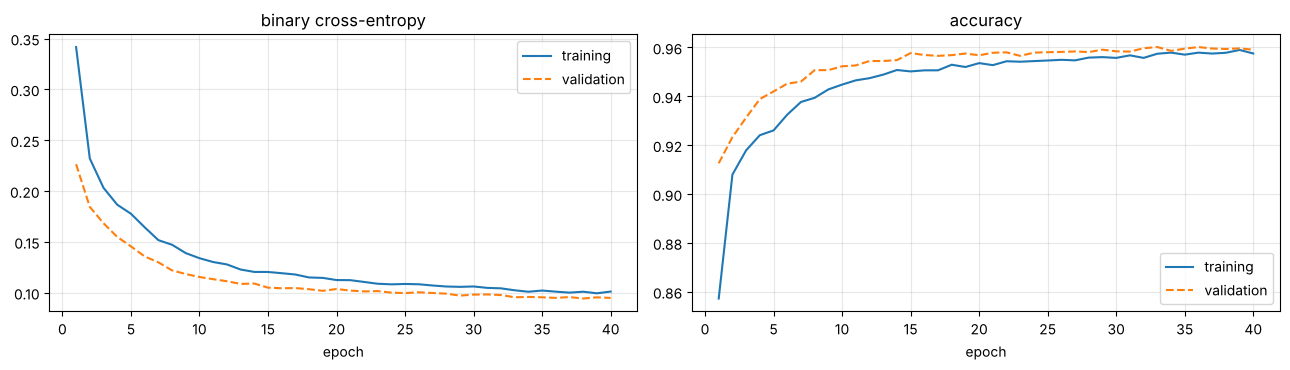

In [8]:
ep = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(ep, h["loss"], label="training"); axes[0].plot(ep, h["val_loss"], "--", label="validation"); axes[0].set_title("binary cross-entropy")
axes[1].plot(ep, h["accuracy"], label="training"); axes[1].plot(ep, h["val_accuracy"], "--", label="validation"); axes[1].set_title("accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6 · Evaluate on the test set

accuracy 96.14% | precision 97.16% | recall 93.84% | F1 95.47% | ROC AUC 0.9946

                      precision    recall  f1-score   support

neutral/dissatisfied     0.9541    0.9790    0.9664     11776
           satisfied     0.9716    0.9384    0.9547      9005

            accuracy                         0.9614     20781
           macro avg     0.9628    0.9587    0.9605     20781
        weighted avg     0.9617    0.9614    0.9613     20781



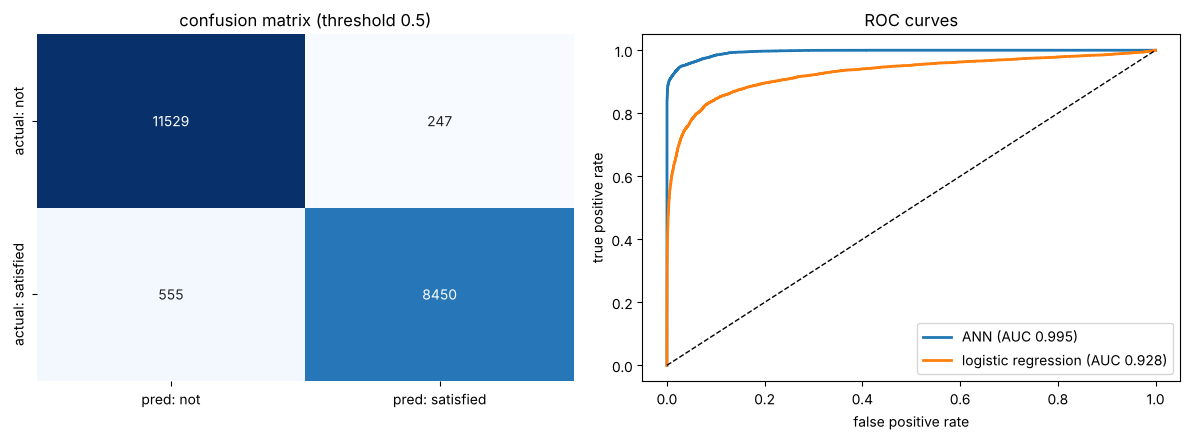

In [9]:
p_ann = model.predict(X_test_s, verbose=0).ravel()
y_hat = (p_ann >= 0.5).astype(int)
print(f"accuracy {accuracy_score(y_test, y_hat):.2%} | precision {precision_score(y_test, y_hat):.2%} | recall {recall_score(y_test, y_hat):.2%} | F1 {f1_score(y_test, y_hat):.2%} | ROC AUC {roc_auc_score(y_test, p_ann):.4f}")
print()
print(classification_report(y_test, y_hat, target_names=["neutral/dissatisfied", "satisfied"], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, y_hat), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred: not", "pred: satisfied"], yticklabels=["actual: not", "actual: satisfied"])
axes[0].set_title("confusion matrix (threshold 0.5)")
for name, pr in [("ANN", p_ann), ("logistic regression", p_lr)]:
    fpr, tpr, _ = roc_curve(y_test, pr); axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, pr):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].legend(); axes[1].set_title("ROC curves")
plt.tight_layout(); plt.show()

**Results on 20,781 test passengers:**
- **Accuracy 96.14%**, ROC AUC **0.995**. Compare: majority baseline 56.7%, **logistic regression 87.6%** (AUC 0.928).
- The hidden layers are worth **+8.5 points** over a single neuron. That fits the EDA: the important relationships are **non-linear** (the U-shaped wifi effect, interactions like "personal trip in Eco"), which one sigmoid neuron can't bend around.
- **Precision 97.2%** (when it says "satisfied", it's almost always right) and **recall 93.8%** (it finds 94% of the satisfied passengers). Its errors lean towards under-calling satisfaction.
- Training ran all 40 epochs, with the best validation loss at epoch 38, so a few more epochs might help a little.

### The threshold is a choice, not a law
The sigmoid outputs a probability; **0.5 is only the default cut-off**. If the airline wants to find as many unhappy passengers as possible (to contact them), it might lower the bar for "not satisfied". Watch precision and recall trade off:

In [10]:
print(f"{'threshold':>9} {'precision':>10} {'recall':>8} {'F1':>7} {'accuracy':>9}   (for the 'satisfied' class)")
for t in [0.2, 0.35, 0.5, 0.65, 0.8]:
    yh = (p_ann >= t).astype(int)
    print(f"{t:>9} {precision_score(y_test, yh):>10.3f} {recall_score(y_test, yh):>8.3f} {f1_score(y_test, yh):>7.3f} {accuracy_score(y_test, yh):>9.3f}")

threshold  precision   recall      F1  accuracy   (for the 'satisfied' class)
      0.2      0.867    0.988   0.924     0.929
     0.35      0.957    0.951   0.954     0.960
      0.5      0.972    0.938   0.955     0.961
     0.65      0.988    0.913   0.949     0.957
      0.8      0.996    0.895   0.942     0.953


- Threshold **0.2:** recall 0.988 (finds nearly every satisfied passenger) but precision falls to 0.867.
- Threshold **0.8:** precision 0.996 but recall 0.895.
- Accuracy and F1 peak around **0.35–0.5**, so the default is sensible here. Choose the threshold by the **cost of each kind of mistake**, not by habit.

## 7 · Which features drive the predictions? (permutation importance)
Shuffle one column in the test set (breaking its link with the answer) and measure how much accuracy drops. A big drop = the model relies on that feature.

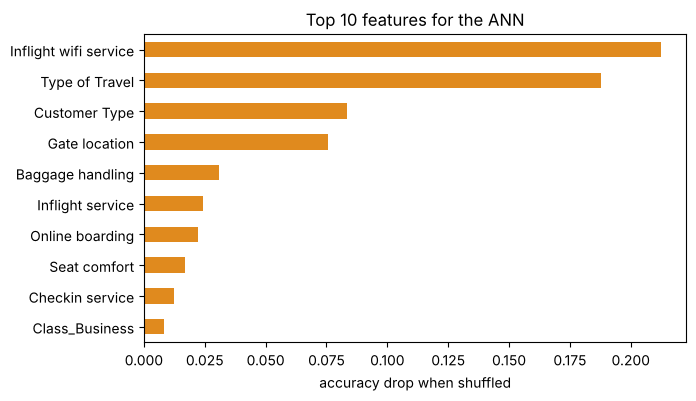

Inflight wifi service    0.2122
Type of Travel           0.1877
Customer Type            0.0836
Gate location            0.0755
Baggage handling         0.0307
Inflight service         0.0242
Online boarding          0.0224
Seat comfort             0.0170


In [11]:
rng = np.random.default_rng(0)
sub = rng.choice(len(X_test_s), 8000, replace=False)
Xs, ys = X_test_s[sub], y_test[sub]
base = accuracy_score(ys, model.predict(Xs, verbose=0).ravel() >= 0.5)
drops = {}
for j, col in enumerate(X.columns):
    Xp = Xs.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
    drops[col] = base - accuracy_score(ys, model.predict(Xp, verbose=0).ravel() >= 0.5)
imp = pd.Series(drops).sort_values(ascending=False)
imp.head(10).iloc[::-1].plot.barh(figsize=(7, 4), color="#e08a1e"); plt.xlabel("accuracy drop when shuffled"); plt.title("Top 10 features for the ANN"); plt.show()
print(imp.head(8).round(4).to_string())

**What the network relies on:** shuffling **Inflight wifi** drops accuracy by **21 points**, **Type of Travel** by 19, Customer Type by 8, **Gate location** by 8. Note that wifi and gate location had **weak correlations** (0.28 and 0.001) but are among the most important features to the network: it uses their **non-linear** (U-shaped) patterns. **Correlation ≠ importance.**

*Caution:* permutation importance shows what **this model** uses, not what **causes** satisfaction, and correlated features can share or hide each other's importance.

## 8 · A random forest for comparison

In [12]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42).fit(X_train, y_train)
p_rf = rf.predict_proba(X_test)[:, 1]
print(f"random forest: {time.time() - t0:.0f} s | accuracy {accuracy_score(y_test, p_rf >= 0.5):.2%} | ROC AUC {roc_auc_score(y_test, p_rf):.4f}")

random forest: 4 s | accuracy 96.16% | ROC AUC 0.9940


## 9 · Predict for a new passenger

In [13]:
new = pd.DataFrame([{**{c: 0 for c in X.columns},
    "Gender": 1, "Customer Type": 1, "Age": 35, "Type of Travel": 1, "Flight Distance": 1200,
    **{r: 4 for r in ratings}, "Inflight wifi service": 2, "Online boarding": 5,
    "Departure Delay in Minutes": 10, "Arrival Delay in Minutes": 5, "Class_Business": 1}])[X.columns]
p_new = model.predict(scaler.transform(new), verbose=0)[0, 0]
print(f"loyal business traveller in Business class, mostly 4/5 ratings, online boarding 5, wifi 2: P(satisfied) = {p_new:.1%}")
new2 = new.copy(); new2["Type of Travel"] = 0; new2["Class_Business"] = 0; new2["Class_Eco"] = 1; new2["Online boarding"] = 2
print(f"same person, personal trip in Eco, online boarding rated 2:                               P(satisfied) = {model.predict(scaler.transform(new2), verbose=0)[0, 0]:.1%}")

loyal business traveller in Business class, mostly 4/5 ratings, online boarding 5, wifi 2: P(satisfied) = 74.6%
same person, personal trip in Eco, online boarding rated 2:                               P(satisfied) = 0.0%


## 10 · Summary

| Model | Test accuracy | ROC AUC |
|---|---|---|
| always "not satisfied" | 56.67% | n/a |
| logistic regression (one sigmoid neuron) | 87.64% | 0.928 |
| **ANN** (64-32-16, BN, dropout) | **96.14%** | **0.995** |
| random forest (200 trees, 4 s) | 96.16% | 0.994 |

**Lessons:**
1. **Clean before modelling:** drop identifiers, one-hot multi-valued categories, impute and scale **using training statistics only**.
2. **Baselines tell you what the model adds:** hidden layers gave +8.5 points over logistic regression because the patterns are non-linear.
3. **Binary = 1 sigmoid unit + binary cross-entropy**, and the **threshold** is a business decision.
4. **Correlation misses non-linear effects**; permutation importance on the trained model reveals them.
5. On this table the ANN and the random forest **tie**. As in case study 1, always compare with a tree ensemble on tabular data.

## ✅ Check yourself
1. Why drop `id` and `Unnamed: 0`? *(identifiers carry no information; the model could memorise noise)*
2. Why one-hot encode Class instead of 0/1/2? *(numbers would invent an order and equal spacing between classes)*
3. Why impute the missing delays with the **training** median? *(using test statistics leaks information)*
4. Output layer and loss for a binary problem? *(1 sigmoid unit + binary cross-entropy)*
5. Logistic regression = which neural network? *(a single sigmoid neuron, no hidden layer)*
6. Lowering the threshold from 0.5 to 0.2 for "satisfied": what happens to recall and precision? *(recall up, precision down)*
7. What does permutation importance measure? *(how much the score drops when one feature's link with the target is destroyed)*